# Customer Behavior Analysis and Repeat Purchase Prediction

## Project Overview

This project analyses online retail transaction data to understand customer purchasing behaviour and predict the likelihood of customers making repeat purchases within the next 60 days.

## Objectives

- Analyse sales and customer purchasing patterns.
- Perform customer segmentation using RFM analysis.
- Identify factors associated with repeat purchasing.
- Build a machine learning model to predict repeat purchases.
- Evaluate model performance using appropriate classification metrics.

## Dataset

**Source:** UCI Online Retail Dataset

The dataset contains online retail transactions from a UK-based retailer between December 2010 and December 2011.

## Tools and Technologies

- Python
- Pandas and NumPy
- Matplotlib and Seaborn
- Scikit-learn
- Google Colab

## Project Workflow

1. Data loading and preprocessing
2. Exploratory Data Analysis
3. Customer segmentation
4. Feature engineering
5. Repeat purchase prediction
6. Model evaluation
7. Results and interpretation


## 1. Environment Setup and Data Loading

This section imports the required Python libraries, verifies the dataset file and loads the UCI Online Retail dataset into a Pandas DataFrame.

In [60]:

# Project 1: Customer Behavior Analysis

# Import the required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)

print("Customer Behavior Analysis Project")
print("Environment setup completed!")


Customer Behavior Analysis Project
Environment setup completed!


In [62]:

!pip install -q openpyxl


### 1.1 Verify Dataset File

Verify the dataset's availability, file size and Excel file structure before loading it into Pandas.

In [63]:

import os
import zipfile

file_path = "/content/Online Retail.xlsx"

print("File exists:", os.path.exists(file_path))

if os.path.exists(file_path):
    print("File size:", os.path.getsize(file_path), "bytes")
    print("Valid Excel ZIP structure:", zipfile.is_zipfile(file_path))


File exists: True
File size: 23715344 bytes
Valid Excel ZIP structure: True


### 1.2 Load the Dataset

Load the UCI Online Retail Excel dataset into a Pandas DataFrame using `read_excel()`.

Display the dataset dimensions and first five records to verify successful loading.

In [64]:

import pandas as pd

df = pd.read_excel("/content/Online Retail.xlsx")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()


Dataset loaded successfully!
Dataset shape: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


### 1.3 Initial Dataset Inspection

Inspect the dataset structure, column names, data types, missing values and duplicate records to understand its initial quality before preprocessing.

In [65]:

print(df.columns.tolist())

df.info()
missing_values = df.isnull().sum()

print(missing_values)

duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)


['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64
Duplicate ro

### 1.4 Remove Duplicate Records

Create a copy of the original dataset and remove duplicate transaction records. Compare the row counts before and after cleaning to identify how many duplicate records were removed.

In [66]:

df_clean = df.copy()

rows_before = len(df_clean)

df_clean = df_clean.drop_duplicates().copy()

rows_after = len(df_clean)

print("Rows before cleaning:", rows_before)
print("Rows after removing duplicates:", rows_after)
print("Duplicate rows removed:", rows_before - rows_after)


Rows before cleaning: 541909
Rows after removing duplicates: 536641
Duplicate rows removed: 5268


### 1.5 Missing Value Analysis

Identify columns containing missing values and summarise their missing counts and percentages to assess data completeness.

In [68]:

missing_report = pd.DataFrame({
    "Missing Count": df_clean.isnull().sum(),
    "Missing Percentage": (df_clean.isnull().mean() * 100).round(2)
})

print(missing_report[missing_report["Missing Count"] > 0])


             Missing Count  Missing Percentage
Description           1454                0.27
CustomerID          135037               25.16


### 1.6 Transaction Quality Analysis

Examine negative and zero quantities, negative unit prices and cancelled invoices to identify unusual transaction records that may affect sales analysis.

In [69]:

print("Negative quantity rows:", (df_clean["Quantity"] < 0).sum())

print("Zero quantity rows:", (df_clean["Quantity"] == 0).sum())

print("Negative price rows:", (df_clean["UnitPrice"] < 0).sum())

print("Cancelled invoice rows:", df_clean["InvoiceNo"].astype(str).str.startswith("C").sum())


Negative quantity rows: 10587
Zero quantity rows: 0
Negative price rows: 2
Cancelled invoice rows: 9251


### 1.7 Inspect Unusual Transactions

Display examples of negative-price records, returned quantities and cancelled invoices to understand their structure and distinguish genuine sales from returns and adjustments.

In [70]:


print("Rows with negative prices")

display(df_clean[df_clean["UnitPrice"] < 0])

print("Sample rows with negative quantities")

display(df_clean[df_clean["Quantity"] < 0].head(10))

print("Sample cancelled invoice rows")

display(
    df_clean[
        df_clean["InvoiceNo"].astype(str).str.startswith("C")
    ].head(10)
)


Rows with negative prices


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Sample rows with negative quantities


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


Sample cancelled invoice rows


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
238,C536391,21980,PACK OF 12 RED RETROSPOT TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom
239,C536391,21484,CHICK GREY HOT WATER BOTTLE,-12,2010-12-01 10:24:00,3.45,17548.0,United Kingdom
240,C536391,22557,PLASTERS IN TIN VINTAGE PAISLEY,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
241,C536391,22553,PLASTERS IN TIN SKULLS,-24,2010-12-01 10:24:00,1.65,17548.0,United Kingdom
939,C536506,22960,JAM MAKING SET WITH JARS,-6,2010-12-01 12:38:00,4.25,17897.0,United Kingdom


### 1.8 Calculate Transaction Revenue

Calculate the transaction value by multiplying quantity by unit price.

\[
Revenue = Quantity \times UnitPrice
\]

Display sample transaction values and calculate the total signed transaction value, including negative values from returns and adjustments.

In [71]:

df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Sample transaction values")

display(
    df_clean[
        ["InvoiceNo", "Quantity", "UnitPrice", "Revenue"]
    ].head(10)
)

print("Total signed transaction value:", round(df_clean["Revenue"].sum(), 2))


Sample transaction values


,InvoiceNo,Quantity,UnitPrice,Revenue
0,536365,6,2.55,15.30
1,536365,6,3.39,20.34
2,536365,8,2.75,22.00
3,536365,6,3.39,20.34
4,536365,6,3.39,20.34
5,536365,2,7.65,15.30
6,536365,6,4.25,25.50
7,536366,6,1.85,11.10
8,536366,6,1.85,11.10
9,536367,32,1.69,54.08


Total signed transaction value: 9726006.95


### 1.9 Classify Transaction Types

Create flags to identify cancelled invoices, returns or adjustments, and valid positive sales.

Filter positive sales into a separate DataFrame (`sales_df`) for subsequent sales and customer behaviour analysis.

A positive sale is defined as a transaction that:
- Is not a cancelled invoice.
- Has a quantity greater than zero.
- Has a unit price greater than zero.

In [72]:

df_clean["IsCancelled"] = df_clean["InvoiceNo"].astype(str).str.startswith("C")

df_clean["IsReturnOrAdjustment"] = df_clean["Quantity"] < 0

df_clean["IsPositiveSale"] = (
    (~df_clean["IsCancelled"])
    & (df_clean["Quantity"] > 0)
    & (df_clean["UnitPrice"] > 0)
)

sales_df = df_clean[df_clean["IsPositiveSale"]].copy()

print("Total cleaned rows:", len(df_clean))
print("Cancelled invoice rows:", df_clean["IsCancelled"].sum())
print("Negative quantity rows:", df_clean["IsReturnOrAdjustment"].sum())
print("Positive sales rows:", len(sales_df))


Total cleaned rows: 536641
Cancelled invoice rows: 9251
Negative quantity rows: 10587
Positive sales rows: 524878


### 1.10 Positive Sales Summary

Calculate key sales metrics using valid positive transactions, excluding cancelled invoices, returns and non-positive prices.

The analysis includes total positive sales value, number of sales records and average transaction-line value.

In [73]:

sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

total_sales = sales_df["Revenue"].sum()

print("Total positive sales value: £", round(total_sales, 2))
print("Number of sales rows:", len(sales_df))
print("Average transaction-line value: £", round(sales_df["Revenue"].mean(), 2))


Total positive sales value: £ 10642110.8
Number of sales rows: 524878
Average transaction-line value: £ 20.28


### 1.11 Export Processed Datasets

Export the cleaned transaction dataset and filtered positive-sales dataset as CSV files for reuse in subsequent analysis and reporting.

In [74]:

df_clean.to_csv("cleaned_online_retail.csv", index=False)

sales_df.to_csv("positive_sales.csv", index=False)

print("Both datasets saved successfully.")


Both datasets saved successfully.


# 2. Exploratory Data Analysis (EDA)

Explore sales trends, customer purchasing patterns, product performance and transaction behaviour using the processed retail dataset.

### 2.1 Prepare Data for EDA

Convert invoice dates into datetime format and extract month, year and hour features for time-based analysis.

In [75]:

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sales_df["InvoiceDate"] = pd.to_datetime(sales_df["InvoiceDate"])
sales_df["Revenue"] = sales_df["Quantity"] * sales_df["UnitPrice"]

sales_df["Month"] = sales_df["InvoiceDate"].dt.to_period("M").astype(str)
sales_df["Year"] = sales_df["InvoiceDate"].dt.year
sales_df["Hour"] = sales_df["InvoiceDate"].dt.hour

print("EDA preparation complete.")


EDA preparation complete.


### 2.2 Monthly Sales Trend

Analyse monthly sales revenue to identify changes in sales performance over the dataset period.

A line chart is used to visualise monthly revenue trends and highlight variations in sales across different months.

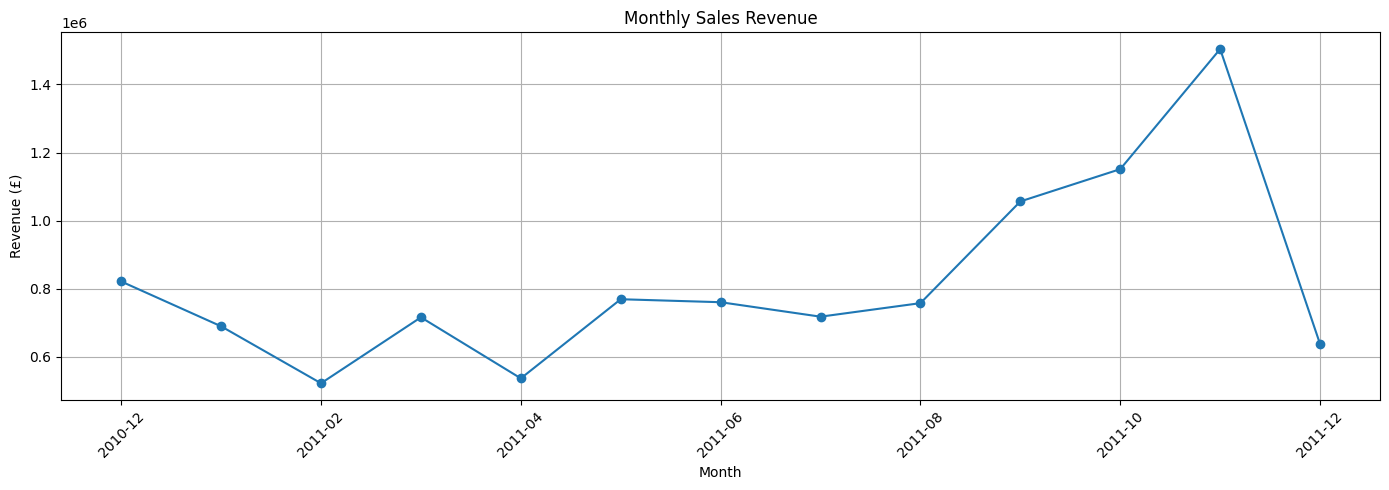

In [76]:

monthly_sales = sales_df.groupby("Month")["Revenue"].sum()

plt.figure(figsize=(14, 5))
monthly_sales.plot(kind="line", marker="o")
plt.title("Monthly Sales Revenue")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()


### 2.3 Top 10 Products by Revenue

Identify the ten products generating the highest sales revenue.

Group transactions by product description, calculate total revenue for each product and visualise the top-performing products using a horizontal bar chart.

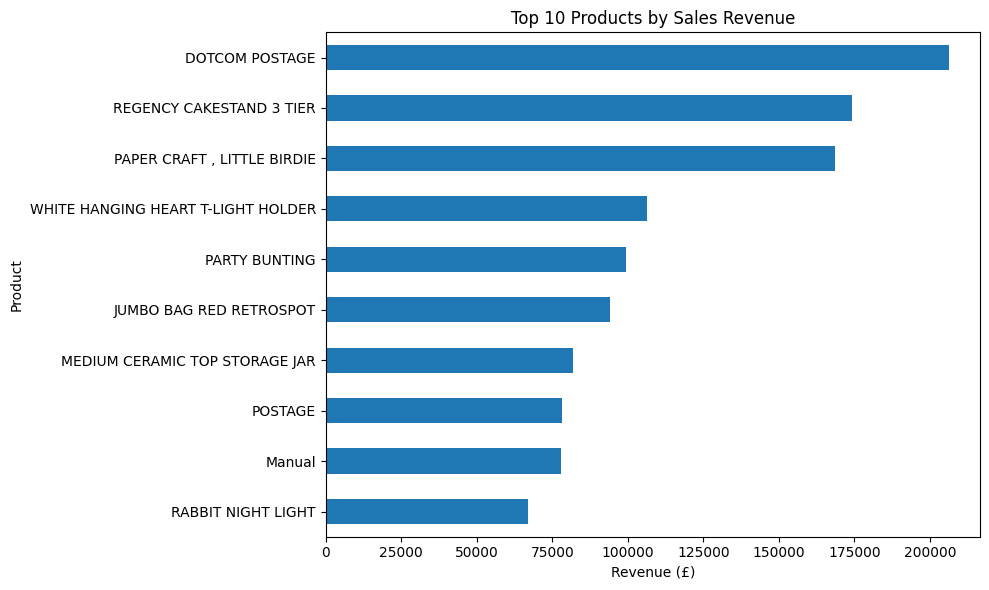

In [77]:

top_products = (
    sales_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
top_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


### 2.4 Sales Revenue by Country

Identify the ten countries generating the highest sales revenue.

Group positive sales transactions by country, calculate total revenue and visualise the top-performing countries using a horizontal bar chart.

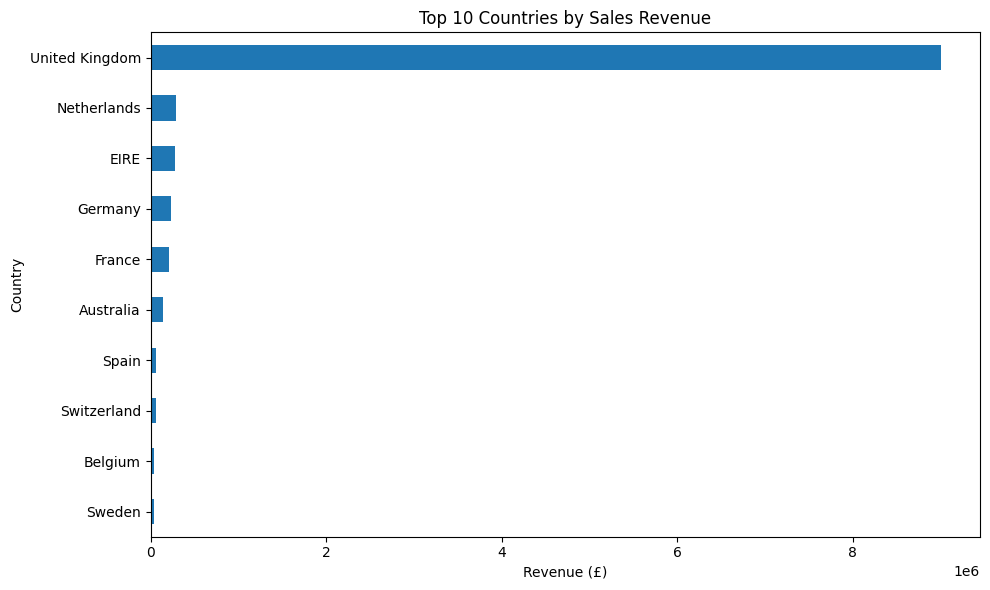

In [78]:

country_sales = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 6))
country_sales.sort_values().plot(kind="barh")
plt.title("Top 10 Countries by Sales Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()


### 2.5 Customer Data Preparation

Prepare customer-level transaction data by excluding records with missing CustomerID values and converting customer IDs into integer format.

Calculate the number of identifiable sales records and unique customers for further customer behaviour analysis.

In [79]:

customer_df = sales_df.dropna(subset=["CustomerID"]).copy()

customer_df["CustomerID"] = customer_df["CustomerID"].astype(int)

print("Identifiable sales rows:", len(customer_df))
print("Unique customers:", customer_df["CustomerID"].nunique())



Identifiable sales rows: 392692
Unique customers: 4338


### 2.6 Top 10 Customers by Revenue

Calculate the total revenue generated by each identifiable customer by grouping transactions using CustomerID.

Sort customers by total revenue in descending order and display the ten highest-revenue customers.

In [80]:

customer_revenue = (
    customer_df.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 customers by revenue")
display(customer_revenue.head(10))


Top 10 customers by revenue


,Revenue
CustomerID,
14646,280206.02
18102,259657.30
17450,194390.79
16446,168472.50
14911,143711.17
12415,124914.53
14156,117210.08
17511,91062.38
16029,80850.84


### 2.7 Top 10 Customers by Purchase Frequency

Calculate the number of unique invoices associated with each customer to measure purchase frequency.

Sort customers by invoice count in descending order and display the ten most frequent customers.

In [81]:

customer_frequency = (
    customer_df.groupby("CustomerID")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 customers by number of invoices")
display(customer_frequency.head(10))


Top 10 customers by number of invoices


,InvoiceNo
CustomerID,
12748,209
14911,201
17841,124
13089,97
14606,93
15311,91
12971,86
14646,73
16029,63


### 2.8 Visualise Top Customers by Revenue

Create a horizontal bar chart to compare the recorded sales revenue generated by the ten highest-revenue customers.

This visualisation helps identify customers who contribute significantly to total sales revenue.

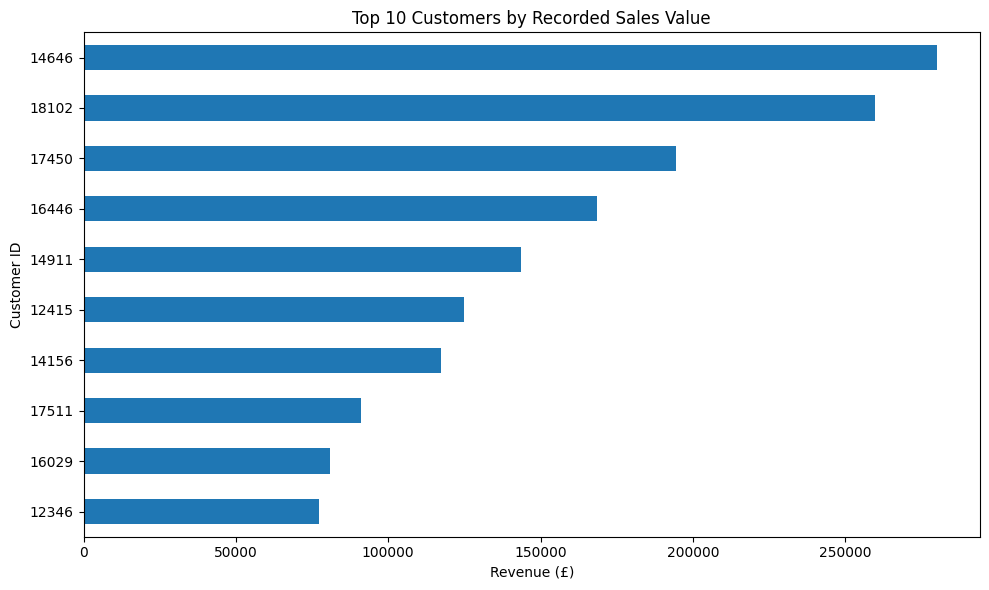

In [82]:

top_customers = customer_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_customers.plot(kind="barh")
plt.title("Top 10 Customers by Recorded Sales Value")
plt.xlabel("Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()


## 3. RFM Customer Segmentation

RFM analysis evaluates customer purchasing behaviour using Recency, Frequency and Monetary value. It helps identify valuable, frequent and inactive customers.

### 3.1 Calculate RFM Metrics

Calculate RFM metrics for each identifiable customer:

- **Recency:** Days since the customer's latest purchase.
- **Frequency:** Number of unique purchase invoices.
- **Monetary:** Total recorded positive sales revenue.

The analysis date is set to one day after the latest transaction in the customer dataset.

In [83]:

import pandas as pd

analysis_date = customer_df["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = customer_df.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda dates: (analysis_date - dates.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("Revenue", "sum")
)

rfm = rfm.reset_index()

display(rfm.head())


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


### 3.2 Calculate RFM Scores

Assign customers scores from 1 to 4 based on the quartile distribution of Recency, Frequency and Monetary values.

- Recency scoring is reversed because lower recency indicates more recent purchasing activity.
- Frequency and Monetary scores are assigned in ascending order.
- Combine the three scores to generate an overall RFM score for each customer.

In [84]:

rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"].astype(str)
    + rfm["F_Score"].astype(str)
    + rfm["M_Score"].astype(str)
)

display(rfm.head())


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346,326,1,77183.60,1,1,4,114
1,12347,2,7,4310.00,4,4,4,444
2,12348,75,4,1797.24,2,3,4,234
3,12349,19,1,1757.55,3,1,4,314
4,12350,310,1,334.40,1,1,2,112


### 3.3 Customer Segmentation

Classify customers into five segments based on their RFM scores.

- **High-Value Active:** High Recency, Frequency and Monetary scores.
- **Loyal Active:** High Recency and Frequency scores.
- **Needs Re-engagement:** Low Recency and high Frequency scores.
- **Recent Customer:** High Recency and low Frequency scores.
- **Other Customers:** Customers who do not meet the above conditions.

This segmentation helps understand customer purchasing patterns and identify groups that may require different engagement strategies.

In [85]:

def segment_customer(row):
    if row["R_Score"] >= 3 and row["F_Score"] >= 3 and row["M_Score"] >= 3:
        return "High-Value Active"
    elif row["R_Score"] >= 3 and row["F_Score"] >= 3:
        return "Loyal Active"
    elif row["R_Score"] <= 2 and row["F_Score"] >= 3:
        return "Needs Re-engagement"
    elif row["R_Score"] >= 3 and row["F_Score"] <= 2:
        return "Recent Customer"
    else:
        return "Other Customers"

rfm["Segment"] = rfm.apply(segment_customer, axis=1)

display(rfm.head())


,CustomerID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,Segment
0,12346,326,1,77183.60,1,1,4,114,Other Customers
1,12347,2,7,4310.00,4,4,4,444,High-Value Active
2,12348,75,4,1797.24,2,3,4,234,Needs Re-engagement
3,12349,19,1,1757.55,3,1,4,314,Recent Customer
4,12350,310,1,334.40,1,1,2,112,Other Customers


### 3.4 Visualise Customer Segment Distribution

Calculate the number of customers in each RFM segment and display the distribution using a bar chart.

This visualisation helps compare customer groups and understand how customers are distributed across the defined segments.

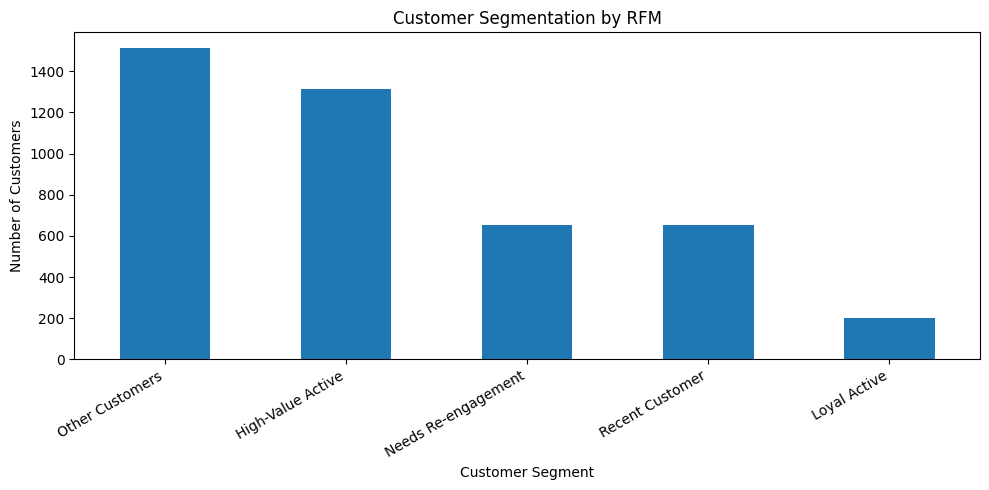

In [86]:

segment_counts = rfm["Segment"].value_counts()

plt.figure(figsize=(10, 5))
segment_counts.plot(kind="bar")
plt.title("Customer Segmentation by RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


### 3.5 Customer Segment Performance Analysis

Compare customer segments using customer count, average recency, purchase frequency, and monetary value. Calculate each segment's share of total customers and revenue to understand its contribution to the business.

In [89]:

segment_summary = rfm.groupby("Segment").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Recency=("Recency", "mean"),
    Average_Frequency=("Frequency", "mean"),
    Total_Monetary=("Monetary", "sum"),
    Average_Monetary=("Monetary", "mean")
).round(2)

segment_summary["Customer_Percentage"] = (
    segment_summary["Customer_Count"]
    / segment_summary["Customer_Count"].sum()
    * 100
).round(2)

segment_summary["Revenue_Percentage"] = (
    segment_summary["Total_Monetary"]
    / segment_summary["Total_Monetary"].sum()
    * 100
).round(2)

display(segment_summary.sort_values("Total_Monetary", ascending=False))


,Customer_Count,Average_Recency,Average_Frequency,Total_Monetary,Average_Monetary,Customer_Percentage,Revenue_Percentage
Segment,,,,,,,
High-Value Active,1312,16.98,9.40,6476424.83,4936.30,30.24,72.87
Needs Re-engagement,655,118.26,4.18,1052403.65,1606.72,15.10,11.84
Other Customers,1514,185.68,1.25,770985.61,509.24,34.90,8.68
Recent Customer,655,24.86,1.45,493878.82,754.01,15.10,5.56
Loyal Active,202,21.20,3.05,93515.98,462.95,4.66,1.05


### 3.6 Export RFM Segmentation Results

Save the RFM metrics, customer scores, and assigned segments to a CSV file for future analysis and reporting.

In [ ]:

rfm.to_csv("customer_rfm_segments.csv", index=False)

print("RFM segmentation saved successfully.")


## 4. Project Summary and Key Business Metrics

Summarise the key findings from the customer behaviour analysis using overall customer, invoice, product, revenue, and country-level metrics.

In [90]:

total_customers = customer_df["CustomerID"].nunique()

total_sales_value = sales_df["Revenue"].sum()

total_invoices = sales_df["InvoiceNo"].nunique()

total_products = sales_df["StockCode"].nunique()

top_country = (
    sales_df.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

print("CUSTOMER BEHAVIOR ANALYSIS")
print("Identifiable customers:", total_customers)
print("Distinct sales invoices:", total_invoices)
print("Distinct product codes:", total_products)
print("Positive sales value: £", round(total_sales_value, 2))
print("Highest-revenue country:", top_country.index[0])


CUSTOMER BEHAVIOR ANALYSIS
Identifiable customers: 4338
Distinct sales invoices: 19960
Distinct product codes: 3922
Positive sales value: £ 10642110.8
Highest-revenue country: United Kingdom


## 5. Repeat Purchase Prediction – Final Modelling Workflow

Develop a customer-level classification model to predict repeat purchases. This workflow includes data preprocessing, feature engineering, model training, baseline comparison, and performance evaluation.

### 5.1 Import Libraries and Inspect Dataset

Import the required data analysis and machine learning libraries, then verify the dataset dimensions and available columns.

In [91]:

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

print("Libraries imported successfully")
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())


Libraries imported successfully
Dataset shape: (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']


### 5.2 Validate and Clean Transaction Data

Prepare the transaction dataset for repeat-purchase modelling.

- Verify that all required columns are available.
- Convert dates and numerical fields into appropriate data types.
- Calculate transaction-level revenue.
- Exclude cancelled invoices, invalid dates, non-positive quantities, and non-positive prices.
- Retain missing CustomerID records temporarily for transaction-level consistency; exclude them when creating customer-level features.

In [92]:

required_columns = [
    "InvoiceNo",
    "StockCode",
    "Quantity",
    "InvoiceDate",
    "UnitPrice",
    "CustomerID"
]

missing_columns = [
    col for col in required_columns
    if col not in df.columns
]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

transactions = df_clean.copy()

transactions["InvoiceDate"] = pd.to_datetime(
    transactions["InvoiceDate"],
    errors="coerce"
)

transactions["Quantity"] = pd.to_numeric(
    transactions["Quantity"],
    errors="coerce"
)

transactions["UnitPrice"] = pd.to_numeric(
    transactions["UnitPrice"],
    errors="coerce"
)

transactions["CustomerID"] = pd.to_numeric(
    transactions["CustomerID"],
    errors="coerce"
)

transactions["LineValue"] = (
    transactions["Quantity"] * transactions["UnitPrice"]
)

valid_sales = transactions[
    transactions["InvoiceNo"].notna()
    & transactions["StockCode"].notna()
    & ~transactions["InvoiceNo"].astype(str).str.startswith("C")
    & (transactions["Quantity"] > 0)
    & (transactions["UnitPrice"] > 0)
    & transactions["InvoiceDate"].notna()
].copy()

valid_sales["CustomerID"] = valid_sales["CustomerID"].astype("Int64")

print("Total transaction rows:", len(transactions))
print("Valid positive-sale rows:", len(valid_sales))
print("Identified customers:", valid_sales["CustomerID"].nunique())
print("Missing CustomerID rows:", valid_sales["CustomerID"].isna().sum())
print("Date range:", valid_sales["InvoiceDate"].min(),
      "to", valid_sales["InvoiceDate"].max())


Total transaction rows: 536641
Valid positive-sale rows: 524878
Identified customers: 4338
Missing CustomerID rows: 132186
Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


### 5.3 Define Historical and Prediction Windows

Use 1 October 2011 as the historical cutoff date and the following 60 days as the prediction window.

- **Historical period:** Transactions before 1 October 2011.
- **Prediction period:** Transactions from 1 October 2011 up to, but not including, 30 November 2011.
- **Target:** Customers who make at least one purchase during the prediction period are labelled as repeat purchasers (1); others are labelled (0).

Create the customer cohort using customers with at least one historical purchase.

In [93]:

cutoff_date = pd.Timestamp("2011-10-01")
prediction_end = cutoff_date + pd.Timedelta(days=60)

identified_sales = valid_sales[
    valid_sales["CustomerID"].notna()
].copy()

history = identified_sales[
    identified_sales["InvoiceDate"] < cutoff_date
].copy()

future = identified_sales[
    (identified_sales["InvoiceDate"] >= cutoff_date)
    & (identified_sales["InvoiceDate"] < prediction_end)
].copy()

future_buyers = set(future["CustomerID"].unique())

customer_target = pd.DataFrame({
    "CustomerID": history["CustomerID"].unique()
})

customer_target["RepeatPurchase60d"] = (
    customer_target["CustomerID"].isin(future_buyers).astype(int)
)

print("Historical cutoff:", cutoff_date.date())
print("Prediction window:", cutoff_date.date(),
      "to", (prediction_end - pd.Timedelta(days=1)).date())
print("Customers in historical cohort:", len(customer_target))
print("Repeat purchasers:", customer_target["RepeatPurchase60d"].sum())
print("Non-repeat purchasers:",
      (customer_target["RepeatPurchase60d"] == 0).sum())
print("Target rate:",
      round(customer_target["RepeatPurchase60d"].mean() * 100, 2), "%")


Historical cutoff: 2011-10-01
Prediction window: 2011-10-01 to 2011-11-29
Customers in historical cohort: 3616
Repeat purchasers: 1708
Non-repeat purchasers: 1908
Target rate: 47.23 %


### 5.4 Generate Customer-Level Features

Aggregate historical transactions to create customer-level features for machine learning.

The following features are calculated:

- **RecencyDays:** Number of days since the customer's last purchase.
- **Frequency:** Number of distinct invoices.
- **Monetary:** Total historical purchase value.
- **TotalQuantity:** Total quantity of products purchased.
- **UniqueProducts:** Number of distinct products purchased.

Merge these features with the 60-day repeat-purchase target and inspect the resulting dataset for missing values and class distribution.

In [94]:

reference_date = cutoff_date

customer_features = (
    history.groupby("CustomerID")
    .agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineValue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )
    .reset_index()
)

customer_features["RecencyDays"] = (
    reference_date - customer_features["LastPurchase"]
).dt.days

customer_features = customer_features.drop(
    columns=["LastPurchase"]
)

model_data = customer_features.merge(
    customer_target,
    on="CustomerID",
    how="inner",
    validate="one_to_one"
)

print("Customer feature table shape:", model_data.shape)
print("\nSample rows:")
display(model_data.head())

print("\nTarget distribution:")
print(model_data["RepeatPurchase60d"].value_counts())

print("\nMissing values:")
print(model_data.isna().sum())


Customer feature table shape: (3616, 7)

Sample rows:


,CustomerID,Frequency,Monetary,TotalQuantity,UniqueProducts,RecencyDays,RepeatPurchase60d
0,12346,1,77183.60,74215,1,255,0
1,12347,5,2790.86,1590,82,59,1
2,12348,4,1797.24,2341,22,5,0
3,12350,1,334.40,197,17,240,0
4,12352,7,2194.31,409,47,2,1



Target distribution:
RepeatPurchase60d
0    1908
1    1708
Name: count, dtype: int64

Missing values:
CustomerID           0
Frequency            0
Monetary             0
TotalQuantity        0
UniqueProducts       0
RecencyDays          0
RepeatPurchase60d    0
dtype: int64


### 5.5 Split Data into Training and Testing Sets

Separate the customer features and target variable for model development.

- **Training set:** 80% of the customer records.
- **Testing set:** 20% of the customer records.
- **Stratified sampling:** Maintains the target class distribution in both sets.
- **Random state:** 42 ensures reproducibility.

Display the sample counts and target distribution to verify the split.

In [95]:

from sklearn.model_selection import train_test_split

feature_columns = [
    "RecencyDays",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts"
]

X = model_data[feature_columns].copy()
y = model_data["RepeatPurchase60d"].copy()

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining target distribution:")
print(y_train.value_counts())
print("\nTesting target distribution:")
print(y_test.value_counts())


Training samples: 2892
Testing samples: 724

Training target distribution:
RepeatPurchase60d
0    1526
1    1366
Name: count, dtype: int64

Testing target distribution:
RepeatPurchase60d
0    382
1    342
Name: count, dtype: int64


### 5.6 Build and Train the Logistic Regression Model

Create a machine learning pipeline combining missing-value imputation, feature scaling, and Logistic Regression.

Use median imputation to handle missing values, StandardScaler to normalise numerical features, and balanced class weights to address class imbalance.

Train the pipeline using the training dataset.

In [96]:

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train, y_train)

print("Model training completed successfully!")
print("Training samples:", len(X_train))
print("Features used:", X_train.columns.tolist())


Model training completed successfully!
Training samples: 2892
Features used: ['RecencyDays', 'Frequency', 'Monetary', 'TotalQuantity', 'UniqueProducts']


### 5.7 Evaluate Model Performance Against Baseline

Evaluate the Logistic Regression model and compare its performance with a Dummy Classifier using the test dataset.

Calculate the following metrics:
- Accuracy
- Precision
- Recall
- F1-score
- ROC-AUC

Display the confusion matrix and detailed classification report to understand the model's prediction performance.

In [97]:

from sklearn.dummy import DummyClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

baseline = DummyClassifier(strategy="prior")
baseline.fit(X_train, y_train)

model_predictions = model.predict(X_test)
model_probabilities = model.predict_proba(X_test)[:, 1]

baseline_predictions = baseline.predict(X_test)
baseline_probabilities = baseline.predict_proba(X_test)[:, 1]

def evaluate_model(name, y_true, predictions, probabilities):
    print(f"\n{name}")
    print("-" * 40)
    print("Accuracy:", round(accuracy_score(y_true, predictions), 4))
    print("Precision:", round(
        precision_score(y_true, predictions, zero_division=0), 4
    ))
    print("Recall:", round(
        recall_score(y_true, predictions, zero_division=0), 4
    ))
    print("F1-score:", round(
        f1_score(y_true, predictions, zero_division=0), 4
    ))

    if y_true.nunique() == 2:
        print("ROC-AUC:", round(
            roc_auc_score(y_true, probabilities), 4
        ))

    print("Confusion matrix:")
    print(confusion_matrix(y_true, predictions))

evaluate_model(
    "Logistic Regression",
    y_test,
    model_predictions,
    model_probabilities
)

evaluate_model(
    "Baseline",
    y_test,
    baseline_predictions,
    baseline_probabilities
)

print("\nDetailed classification report:")
print(classification_report(
    y_test,
    model_predictions,
    zero_division=0
))



Logistic Regression
----------------------------------------
Accuracy: 0.6851
Precision: 0.6952
Recall: 0.5936
F1-score: 0.6404
ROC-AUC: 0.7299
Confusion matrix:
[[293  89]
 [139 203]]

Baseline
----------------------------------------
Accuracy: 0.5276
Precision: 0.0
Recall: 0.0
F1-score: 0.0
ROC-AUC: 0.5
Confusion matrix:
[[382   0]
 [342   0]]

Detailed classification report:
              precision    recall  f1-score   support

           0       0.68      0.77      0.72       382
           1       0.70      0.59      0.64       342

    accuracy                           0.69       724
   macro avg       0.69      0.68      0.68       724
weighted avg       0.69      0.69      0.68       724



### 5.8 Calculate and Export Evaluation Metrics

Calculate accuracy, precision, recall, F1-score, and ROC-AUC for the Logistic Regression model and baseline classifier.

Combine both results into a comparison table and export the evaluation metrics as CSV files for further analysis and reporting.

In [98]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Function to calculate evaluation metrics
def calculate_metrics(name, y_true, predictions, probabilities):
    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": (
            roc_auc_score(y_true, probabilities)
            if y_true.nunique() == 2 else float("nan")
        )
    }
    return results


# Calculate Logistic Regression metrics
metrics_df = pd.DataFrame([
    calculate_metrics(
        "Logistic Regression",
        y_test,
        model_predictions,
        model_probabilities
    )
])

# Calculate baseline metrics
baseline_df = pd.DataFrame([
    calculate_metrics(
        "Baseline",
        y_test,
        baseline_predictions,
        baseline_probabilities
    )
])

# Combine both models for comparison
comparison_df = pd.concat(
    [metrics_df, baseline_df],
    ignore_index=True
)

# Export evaluation results
metrics_df.to_csv("model_evaluation.csv", index=False)
comparison_df.to_csv("model_baseline_comparison.csv", index=False)

print("Evaluation files saved successfully!")

print("\nModel Evaluation:")
display(metrics_df.round(4))

print("\nModel vs Baseline Comparison:")
display(comparison_df.round(4))

Evaluation files saved successfully!

Model Evaluation:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6851,0.6952,0.5936,0.6404,0.7299



Model vs Baseline Comparison:


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.6851,0.6952,0.5936,0.6404,0.7299
1,Baseline,0.5276,0.0000,0.0000,0.0000,0.5000


### 5.9 Visualise Model Performance Comparison

Create a bar chart comparing Logistic Regression and the baseline classifier using precision, recall, F1-score, and ROC-AUC.

Visualise the evaluation metrics to identify differences in predictive performance.

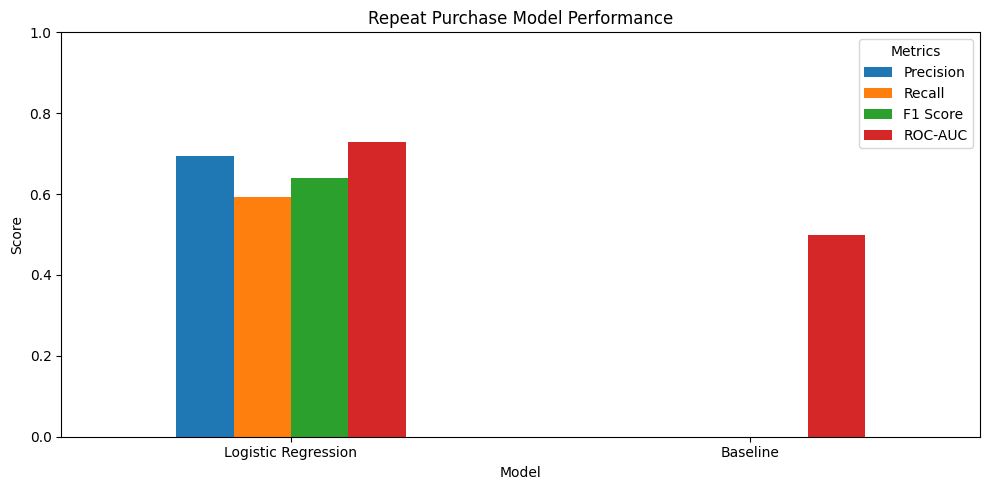

In [100]:
import matplotlib.pyplot as plt

metrics_to_plot = [
    "Precision",
    "Recall",
    "F1 Score",
    "ROC-AUC"
]

comparison_df.set_index("Model")[metrics_to_plot].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.title("Repeat Purchase Model Performance")
plt.xlabel("Model")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(title="Metrics")
plt.tight_layout()
plt.show()

### 5.10 Perform 5-Fold Stratified Cross-Validation

Evaluate the Logistic Regression pipeline using 5-fold stratified cross-validation on the training dataset.

- Divide the training data into five folds.
- Maintain the target class distribution in each fold.
- Train the model on four folds and validate it on the remaining fold.
- Repeat the process five times.
- Calculate the mean and standard deviation of accuracy, precision, recall, F1-score, and ROC-AUC.

Use the results to assess the consistency of model performance across different data splits.

In [101]:
from sklearn.model_selection import StratifiedKFold, cross_validate

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cv_results = cross_validate(
    model,
    X_train,
    y_train,
    cv=cv,
    scoring=["accuracy", "precision", "recall", "f1", "roc_auc"]
)

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    scores = cv_results[f"test_{metric}"]
    print(f"{metric}: {scores.mean():.4f} (+/- {scores.std():.4f})")

accuracy: 0.6881 (+/- 0.0169)
precision: 0.7017 (+/- 0.0166)
recall: 0.5900 (+/- 0.0305)
f1: 0.6409 (+/- 0.0247)
roc_auc: 0.7472 (+/- 0.0163)


### 5.11 Summarise and Export Cross-Validation Results

Create a summary table containing the mean and standard deviation of each evaluation metric across the five validation folds.

Display the results and export them to `cross_validation_results.csv` for model performance analysis and documentation.

In [102]:
cv_summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
    "Mean Score": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Standard Deviation": [
        cv_results["test_accuracy"].std(),
        cv_results["test_precision"].std(),
        cv_results["test_recall"].std(),
        cv_results["test_f1"].std(),
        cv_results["test_roc_auc"].std()
    ]
})

display(cv_summary.round(4))

cv_summary.to_csv("cross_validation_results.csv", index=False)

,Metric,Mean Score,Standard Deviation
0,Accuracy,0.6881,0.0169
1,Precision,0.7017,0.0166
2,Recall,0.5900,0.0305
3,F1-score,0.6409,0.0247
4,ROC-AUC,0.7472,0.0163


### 5.12 Analyse Feature Importance

Extract the Logistic Regression coefficients to examine the contribution of each customer feature to repeat-purchase predictions.

- Positive coefficients indicate an association with repeat purchase.
- Negative coefficients indicate an association with non-repeat purchase.
- Absolute coefficient values help compare the relative importance of features.

Sort the features by absolute coefficient magnitude to identify the strongest model predictors.


In [103]:
classifier = [
    step for step in model.named_steps.values()
    if hasattr(step, "coef_")
][0]

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": classifier.coef_[0]
})

feature_importance["Absolute Importance"] = (
    feature_importance["Coefficient"].abs()
)

feature_importance = feature_importance.sort_values(
    by="Absolute Importance",
    ascending=False
)

display(feature_importance.round(4))

,Feature,Coefficient,Absolute Importance
1,Frequency,1.5626,1.5626
4,UniqueProducts,0.4698,0.4698
0,RecencyDays,-0.2966,0.2966
2,Monetary,-0.1116,0.1116
3,TotalQuantity,0.0011,0.0011


### 5.13 Visualise Feature Importance

Create a horizontal bar chart of Logistic Regression coefficients to compare the contribution of customer features to repeat-purchase predictions.

The zero reference line separates positive and negative coefficients.

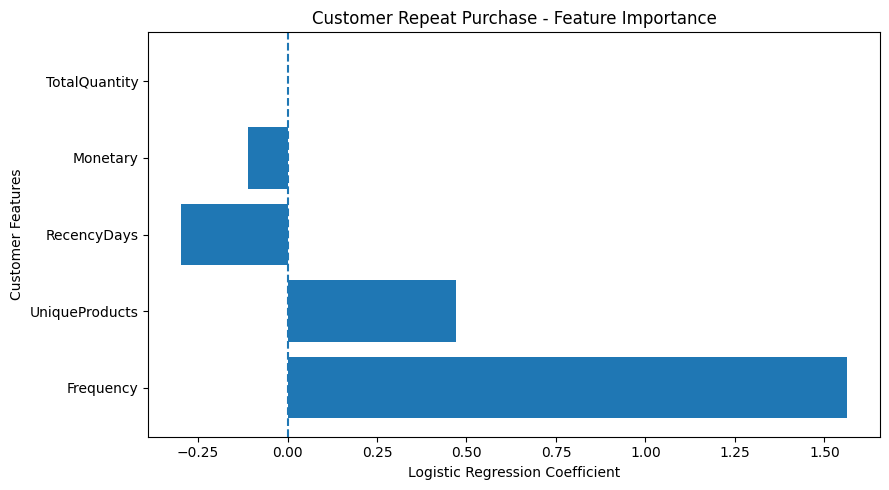

In [104]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Coefficient"]
)

plt.axvline(0, linestyle="--")
plt.title("Customer Repeat Purchase - Feature Importance")
plt.xlabel("Logistic Regression Coefficient")
plt.ylabel("Customer Features")
plt.tight_layout()
plt.show()

### 5.14 Export Feature Importance Results

Save the Logistic Regression feature coefficients and their absolute importance values to a CSV file.

Display the sorted results for future reference, interpretation, and project documentation.

In [105]:
feature_importance.to_csv(
    "customer_feature_importance.csv",
    index=False
)

print("Feature importance saved successfully!")
display(feature_importance.round(4))

Feature importance saved successfully!


,Feature,Coefficient,Absolute Importance
1,Frequency,1.5626,1.5626
4,UniqueProducts,0.4698,0.4698
0,RecencyDays,-0.2966,0.2966
2,Monetary,-0.1116,0.1116
3,TotalQuantity,0.0011,0.0011


### 5.15 Perform Time-Based Model Validation

Evaluate the Logistic Regression model using two separate time-based customer cohorts.

- **Training cohort:** 1 July 2011, using historical transactions before this date and the following 60-day purchase window.
- **Testing cohort:** 1 October 2011, using historical transactions before this date and the following 60-day purchase window.

Generate customer features independently for each snapshot date, train the model on the earlier cohort, and evaluate it on the later cohort.

Measure accuracy, precision, recall, F1-score, ROC-AUC, and the confusion matrix to assess performance across different time periods.

In [106]:
from sklearn.base import clone
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix

def create_customer_cohort(data, snapshot_date):
    snapshot_date = pd.Timestamp(snapshot_date)
    prediction_end = snapshot_date + pd.Timedelta(days=60)

    history = data[
        (data["InvoiceDate"] < snapshot_date) &
        (data["CustomerID"].notna())
    ].copy()

    future = data[
        (data["InvoiceDate"] >= snapshot_date) &
        (data["InvoiceDate"] < prediction_end) &
        (data["CustomerID"].notna())
    ].copy()

    features = history.groupby("CustomerID").agg(
        LastPurchase=("InvoiceDate", "max"),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("LineValue", "sum"),
        TotalQuantity=("Quantity", "sum"),
        UniqueProducts=("StockCode", "nunique")
    )

    features["RecencyDays"] = (
        snapshot_date - features["LastPurchase"]
    ).dt.days

    future_buyers = future["CustomerID"].unique()

    features["RepeatPurchase60d"] = (
        features.index.isin(future_buyers).astype(int)
    )

    return features.drop(columns=["LastPurchase"])


train_cohort = create_customer_cohort(
    valid_sales,
    "2011-07-01"
)

test_cohort = create_customer_cohort(
    valid_sales,
    "2011-10-01"
)

feature_columns = [
    "RecencyDays",
    "Frequency",
    "Monetary",
    "TotalQuantity",
    "UniqueProducts"
]

X_time_train = train_cohort[feature_columns]
y_time_train = train_cohort["RepeatPurchase60d"]

X_time_test = test_cohort[feature_columns]
y_time_test = test_cohort["RepeatPurchase60d"]

time_model = clone(model)
time_model.fit(X_time_train, y_time_train)

time_predictions = time_model.predict(X_time_test)
time_probabilities = time_model.predict_proba(X_time_test)[:, 1]

print("Training customers:", len(X_time_train))
print("Testing customers:", len(X_time_test))

print("\nTime-based validation results")
print("Accuracy:", round(accuracy_score(y_time_test, time_predictions), 4))
print("Precision:", round(precision_score(y_time_test, time_predictions, zero_division=0), 4))
print("Recall:", round(recall_score(y_time_test, time_predictions, zero_division=0), 4))
print("F1-score:", round(f1_score(y_time_test, time_predictions, zero_division=0), 4))
print("ROC-AUC:", round(roc_auc_score(y_time_test, time_probabilities), 4))

print("\nConfusion Matrix:")
print(confusion_matrix(y_time_test, time_predictions))


Training customers: 2960
Testing customers: 3616

Time-based validation results
Accuracy: 0.6892
Precision: 0.6973
Recall: 0.6042
F1-score: 0.6474
ROC-AUC: 0.7434

Confusion Matrix:
[[1460  448]
 [ 676 1032]]


### 5.16 Summarise and Export Time-Based Validation Results

Create a summary table containing the evaluation metrics from the time-based validation.

Display accuracy, precision, recall, F1-score, and ROC-AUC, then export the results to `time_based_validation_results.csv` for reporting and future reference.

In [107]:
time_results = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Score": [
        accuracy_score(y_time_test, time_predictions),
        precision_score(y_time_test, time_predictions, zero_division=0),
        recall_score(y_time_test, time_predictions, zero_division=0),
        f1_score(y_time_test, time_predictions, zero_division=0),
        roc_auc_score(y_time_test, time_probabilities)
    ]
})

display(time_results.round(4))

time_results.to_csv(
    "time_based_validation_results.csv",
    index=False
)

print("Time-based evaluation saved successfully!")

,Metric,Score
0,Accuracy,0.6892
1,Precision,0.6973
2,Recall,0.6042
3,F1-score,0.6474
4,ROC-AUC,0.7434


Time-based evaluation saved successfully!


### 5.17 Final Model Evaluation Summary

Compare the Logistic Regression model's performance across three evaluation approaches:

- **Random Test:** Performance on the 20% held-out test dataset.
- **Cross Validation:** Average performance across five stratified validation folds.
- **Time Based:** Performance on a later customer cohort.

Display the combined evaluation metrics and export the final summary to `final_model_evaluation_summary.csv`.

In [108]:

final_evaluation = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Random Test": [
        accuracy_score(y_test, model_predictions),
        precision_score(y_test, model_predictions, zero_division=0),
        recall_score(y_test, model_predictions, zero_division=0),
        f1_score(y_test, model_predictions, zero_division=0),
        roc_auc_score(y_test, model_probabilities)
    ],
    "Cross Validation": [
        cv_results["test_accuracy"].mean(),
        cv_results["test_precision"].mean(),
        cv_results["test_recall"].mean(),
        cv_results["test_f1"].mean(),
        cv_results["test_roc_auc"].mean()
    ],
    "Time Based": [
        time_results.set_index("Metric").loc[
            ["Accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"],
            "Score"
        ].values
    ][0]
})

display(final_evaluation.round(4))

final_evaluation.to_csv(
    "final_model_evaluation_summary.csv",
    index=False
)

print("Final evaluation summary saved successfully!")

,Metric,Random Test,Cross Validation,Time Based
0,Accuracy,0.6851,0.6881,0.6892
1,Precision,0.6952,0.7017,0.6973
2,Recall,0.5936,0.5900,0.6042
3,F1-score,0.6404,0.6409,0.6474
4,ROC-AUC,0.7299,0.7472,0.7434


Final evaluation summary saved successfully!


### 5.18 Save the Final Model Artifact

Save the trained model and its metadata in a single Joblib file. The artifact includes the feature names, prediction target, prediction window, and training and validation snapshot dates for future use.

In [109]:
import joblib

final_model_artifact = {
    "model": time_model,
    "feature_columns": feature_columns,
    "target": "RepeatPurchase60d",
    "prediction_window_days": 60,
    "training_snapshot": "2011-07-01",
    "validation_snapshot": "2011-10-01"
}

joblib.dump(
    final_model_artifact,
    "final_customer_repeat_purchase_model.joblib"
)

print("Final model saved successfully!")

Final model saved successfully!


### 5.19 Generate and Export Customer Predictions

Generate repeat-purchase predictions for customers in the time-based test cohort. Include the actual outcome, predicted outcome, and predicted probability of repeat purchasing within 60 days. Export the results as a CSV file for further analysis.

In [110]:
prediction_results = pd.DataFrame({
    "CustomerID": X_time_test.index,
    "Actual": y_time_test.values,
    "Predicted": time_predictions,
    "RepeatPurchaseProbability": time_probabilities
})

display(prediction_results.head(10))

prediction_results.to_csv(
    "customer_repeat_purchase_predictions.csv",
    index=False
)

print("Customer predictions exported successfully!")

,CustomerID,Actual,Predicted,RepeatPurchaseProbability
0,12346,0,1,0.842058
1,12347,1,1,0.729345
2,12348,0,1,0.657143
3,12350,0,0,0.195668
4,12352,1,1,0.831916
5,12353,0,0,0.262713
6,12354,0,0,0.300634
7,12355,0,0,0.265286
8,12356,1,0,0.358096
9,12358,0,0,0.319677


Customer predictions exported successfully!


### 5.20 Verify and Package Project Deliverables

Check the availability of the final model, prediction results, evaluation reports, and feature importance file. Package the available deliverables into a single ZIP archive for convenient storage and sharing.

In [111]:

import os
import zipfile

files_to_check = [
    "final_customer_repeat_purchase_model.joblib",
    "customer_repeat_purchase_predictions.csv",
    "final_model_evaluation_summary.csv",
    "cross_validation_results.csv",
    "time_based_validation_results.csv",
    "customer_feature_importance.csv",
    "model_evaluation.csv",
    "model_baseline_comparison.csv"
]

available_files = []
missing_files = []

for file in files_to_check:
    if os.path.exists(file):
        available_files.append(file)
        print(file, "- Available")
    else:
        missing_files.append(file)
        print(file, "- Missing")

zip_name = "Customer_Behavior_Analysis_Deliverables.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as zip_file:
    for file in available_files:
        zip_file.write(file)

print("\nAvailable files:", len(available_files))
print("Missing files:", len(missing_files))
print("ZIP archive created:", zip_name)

if missing_files:
    print("Please check the missing deliverables.")
else:
    print("All project deliverables packaged successfully!")


final_customer_repeat_purchase_model.joblib - Available
customer_repeat_purchase_predictions.csv - Available
final_model_evaluation_summary.csv - Available
cross_validation_results.csv - Available
time_based_validation_results.csv - Available
customer_feature_importance.csv - Available
model_evaluation.csv - Available
model_baseline_comparison.csv - Available

Available files: 8
Missing files: 0
ZIP archive created: Customer_Behavior_Analysis_Deliverables.zip
All project deliverables packaged successfully!


## 6. Conclusion and Future Improvements

### Conclusion

This project analysed customer purchasing behaviour using the UCI Online Retail dataset. Exploratory Data Analysis and RFM segmentation were used to identify sales patterns and understand customer value.

A Logistic Regression model was developed to predict whether a customer would make another purchase within the next 60 days. The model was evaluated using a random test split, stratified cross-validation, and time-based validation.

The time-based evaluation achieved:

- **Accuracy:** 68.92%
- **Precision:** 69.73%
- **Recall:** 60.42%
- **F1-score:** 64.74%
- **ROC-AUC:** 74.34%

RFM analysis showed that High-Value Active Customers contributed approximately 72.87% of total recorded revenue while representing 30.24% of identified customers.

### Business Applications

- Identify high-value customers for targeted retention campaigns.
- Support customer segmentation and marketing decisions.
- Identify customers who may be likely to purchase again.
- Help businesses plan customer engagement strategies.

### Future Improvements

- Experiment with Random Forest and Gradient Boosting models.
- Perform hyperparameter tuning.
- Explore additional customer behaviour features.
- Improve recall while maintaining precision.
- Develop an interactive dashboard for business users.

### Final Note

This project demonstrates the application of data analysis, customer segmentation, feature engineering, and machine learning to a real-world retail business problem.